In [ ]:
!unzip /content/dataset.zip

unzip:  cannot find or open /content/dataset.zip, /content/dataset.zip.zip or /content/dataset.zip.ZIP.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf

In [ ]:
!pip install split-folders

In [ ]:
import splitfolders
splitfolders.ratio('/content/Plant_leave_diseases_dataset_with_augmentation', output="dataset", seed=1337, ratio=(.8, .1,.1))

Copying files: 61486 files [00:20, 3065.77 files/s]


In [ ]:
train_dir = "/content/dataset/train"
validation_dir = "/content/dataset/val"

BATCH_SIZE = 32
IMG_SIZE = (160, 160)

train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir,
                                                            shuffle=True,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE)

Found 49179 files belonging to 39 classes.


In [ ]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(validation_dir,
                                                                 shuffle=True,
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)
test_dir = "/content/dataset/test"
test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir,
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)

Found 6139 files belonging to 39 classes.
Found 6168 files belonging to 39 classes.


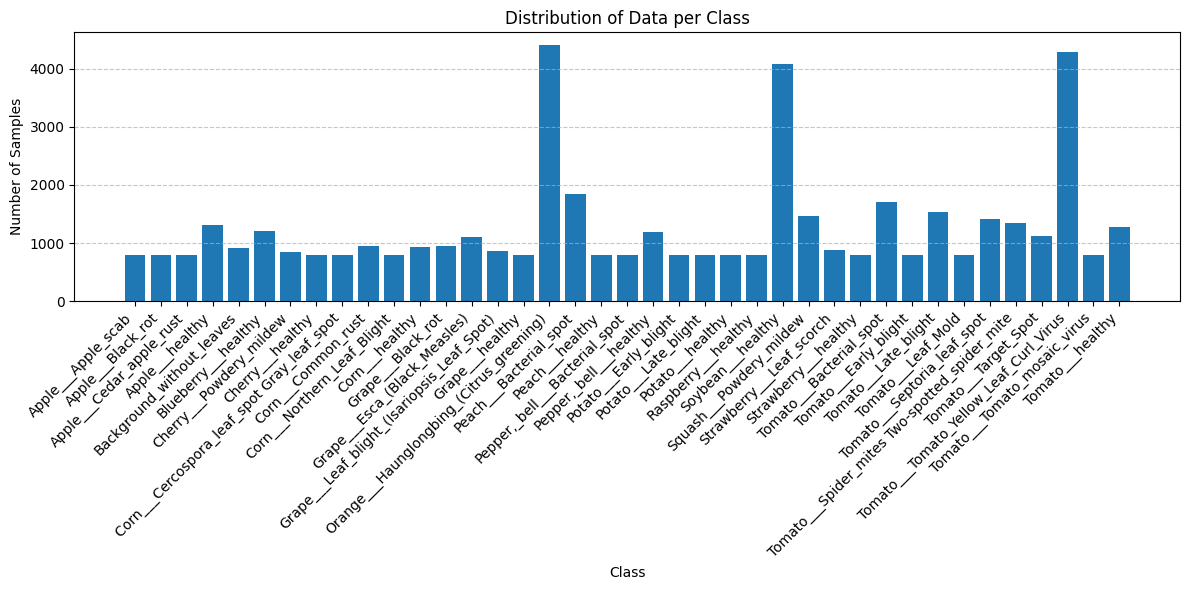

Apple___Apple_scab: 800
Apple___Black_rot: 800
Apple___Cedar_apple_rust: 800
Apple___healthy: 1316
Background_without_leaves: 914
Blueberry___healthy: 1201
Cherry___Powdery_mildew: 841
Cherry___healthy: 800
Corn___Cercospora_leaf_spot Gray_leaf_spot: 800
Corn___Common_rust: 953
Corn___Northern_Leaf_Blight: 800
Corn___healthy: 929
Grape___Black_rot: 944
Grape___Esca_(Black_Measles): 1106
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 860
Grape___healthy: 800
Orange___Haunglongbing_(Citrus_greening): 4405
Peach___Bacterial_spot: 1837
Peach___healthy: 800
Pepper,_bell___Bacterial_spot: 800
Pepper,_bell___healthy: 1182
Potato___Early_blight: 800
Potato___Late_blight: 800
Potato___healthy: 800
Raspberry___healthy: 800
Soybean___healthy: 4072
Squash___Powdery_mildew: 1468
Strawberry___Leaf_scorch: 887
Strawberry___healthy: 800
Tomato___Bacterial_spot: 1701
Tomato___Early_blight: 800
Tomato___Late_blight: 1527
Tomato___Leaf_Mold: 800
Tomato___Septoria_leaf_spot: 1416
Tomato___Spider_mites Two-sp

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
counts = np.zeros(len(class_names), dtype=int)
for images, labels in train_dataset:
    batch_labels = labels.numpy()
    unique, batch_counts = np.unique(batch_labels, return_counts=True)
    for u, c in zip(unique, batch_counts):
        counts[u] += c
plt.figure(figsize=(12, 6))
plt.bar(class_names, counts)
plt.title('Distribution of Data per Class')
plt.xlabel('Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
for class_name, count in zip(class_names, counts):
    print(f"{class_name}: {count}")

In [ ]:
class_names = train_dataset.class_names

plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

In [ ]:
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Background_without_leaves',
 'Blueberry___healthy',
 'Cherry___Powdery_mildew',
 'Cherry___healthy',
 'Corn___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn___Common_rust',
 'Corn___Northern_Leaf_Blight',
 'Corn___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Target_Spot'

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [ ]:
preprocess_input = tf.keras.applications.efficientnet.preprocess_input

In [ ]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.EfficientNetB4(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet',
)

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 5, 5, 1792)


In [ ]:
!wget -O "dataset.zip" "https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded"

--2025-12-30 06:02:26--  https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/b4e3a32f-c0bd-4060-81e9-6144231f2520/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd [following]
--2025-12-30 06:02:27--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/349ac012-2948-4172-bbba-3bf8f76596fd
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 52.218.62.16, 52.218.29.184, 52.92.20.66, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|52.218.62.16|:443

In [ ]:
base_model.trainable = False

In [ ]:
base_model.summary()

Model: "efficientnetb4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 160, 160,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 160, 160,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 160, 160,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 161, 161,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 80, 80,    │      1,296 │ stem_conv_pad[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 80, 80,    │        192 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 80, 80,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 80, 80,    │        432 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 80, 80,    │        192 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 80, 80,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 48)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 48)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 12)  │        588 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 48)  │        624 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 80, 80,    │          0 │ block1a_activati… │
│ (Multiply)          │ 48)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 80, 80,    │      1,152 │ block1a_se_excit

 Total params: 17,673,823 (67.42 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 17,673,823 (67.42 MB)

In [ ]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 1792)


In [ ]:
prediction_layer = tf.keras.layers.Dense(len(class_names), activation='softmax')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 39)


In [ ]:
inputs = tf.keras.Input(shape=(160, 160, 3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb4 (Functional)     │ (None, 5, 5, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 39)             │        69,927 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,743,750 (67.69 MB)

 Trainable params: 69,927 (273.15 KB)

 Non-trainable params: 17,673,823 (67.42 MB)

In [ ]:
len(model.trainable_variables)

2

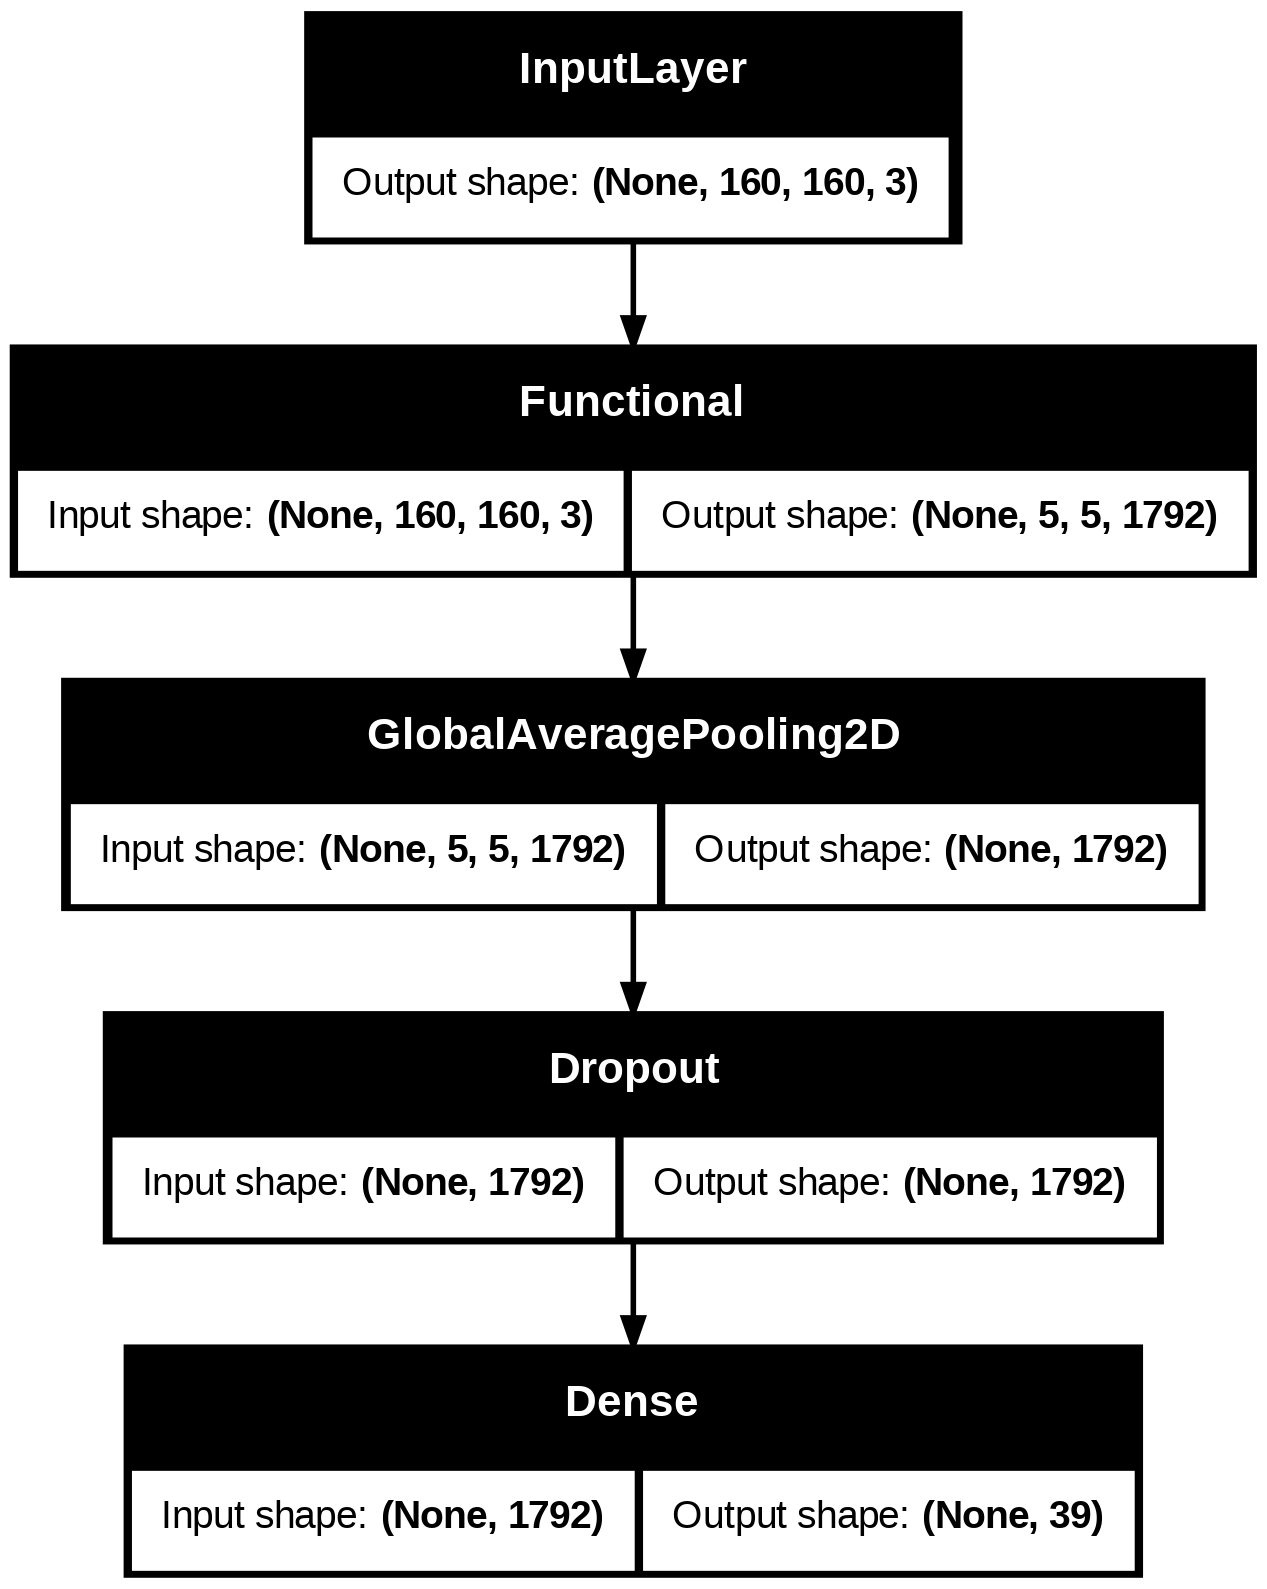

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')])

In [ ]:
initial_epochs = 6

loss0, accuracy0 = model.evaluate(validation_dataset)

192/192 ━━━━━━━━━━━━━━━━━━━━ 45s 128ms/step - accuracy: 0.0181 - loss: 3.7774


In [ ]:
print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

initial loss: 3.78
initial accuracy: 0.02


In [ ]:
history = model.fit(train_dataset,
                    epochs=initial_epochs,
                    validation_data=validation_dataset)

Epoch 1/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 152s 72ms/step - accuracy: 0.7092 - loss: 1.1790 - val_accuracy: 0.9114 - val_loss: 0.3237
Epoch 2/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 91s 59ms/step - accuracy: 0.9034 - loss: 0.3433 - val_accuracy: 0.9304 - val_loss: 0.2381
Epoch 3/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 142s 59ms/step - accuracy: 0.9222 - loss: 0.2598 - val_accuracy: 0.9392 - val_loss: 0.1963
Epoch 4/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 91s 59ms/step - accuracy: 0.9301 - loss: 0.2293 - val_accuracy: 0.9451 - val_loss: 0.1717
Epoch 5/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 92s 60ms/step - accuracy: 0.9359 - loss: 0.2067 - val_accuracy: 0.9456 - val_loss: 0.1667
Epoch 6/6
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 91s 59ms/step - accuracy: 0.9406 - loss: 0.1866 - val_accuracy: 0.9485 - val_loss: 0.1562


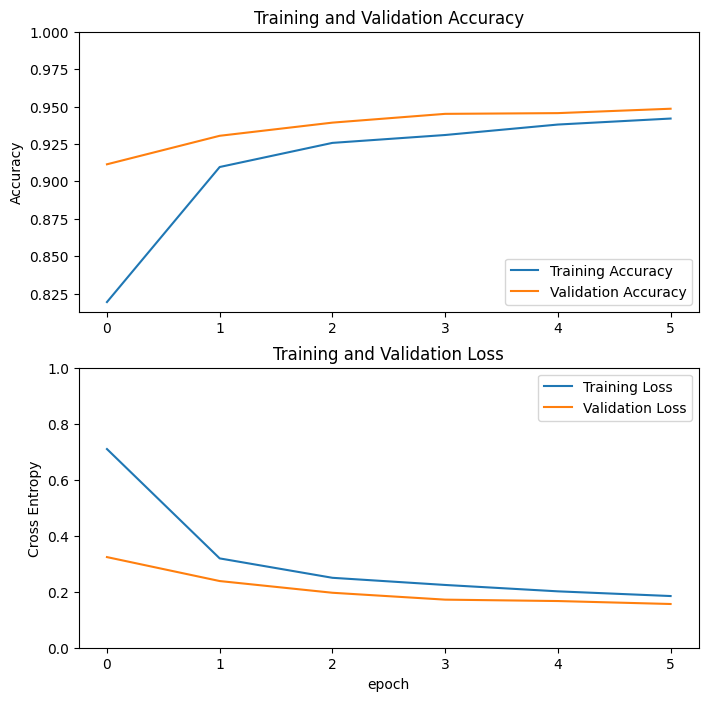

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
base_model.trainable = True

In [ ]:
# Let's take a look to see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model.layers))

# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

Number of layers in the base model:  475


In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')])

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb4 (Functional)     │ (None, 5, 5, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1792)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 39)             │        69,927 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,743,750 (67.69 MB)

 Trainable params: 17,531,783 (66.88 MB)

 Non-trainable params: 211,967 (828.00 KB)

In [ ]:
len(model.trainable_variables)

333

In [ ]:
fine_tune_epochs = 10
total_epochs =  initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         validation_data=validation_dataset)

Epoch 7/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 434s 207ms/step - accuracy: 0.9021 - loss: 0.3772 - val_accuracy: 0.9405 - val_loss: 0.3299
Epoch 8/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 236s 153ms/step - accuracy: 0.9713 - loss: 0.0944 - val_accuracy: 0.9764 - val_loss: 0.0875
Epoch 9/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 235s 153ms/step - accuracy: 0.9784 - loss: 0.0750 - val_accuracy: 0.9835 - val_loss: 0.0599
Epoch 10/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 235s 153ms/step - accuracy: 0.9826 - loss: 0.0558 - val_accuracy: 0.9808 - val_loss: 0.0740
Epoch 11/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 236s 154ms/step - accuracy: 0.9831 - loss: 0.0545 - val_accuracy: 0.9800 - val_loss: 0.0724
Epoch 12/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 236s 153ms/step - accuracy: 0.9867 - loss: 0.0407 - val_accuracy: 0.9899 - val_loss: 0.0482
Epoch 13/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 237s 154ms/step - accuracy: 0.9880 - loss: 0.0391 - val_accuracy: 0.9863 - val_loss: 0.0514
Epoch 14/16
1537/1537 ━━━━━━━━━━━━━━━━━━━━ 236s 153ms/step

In [ ]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']

loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']

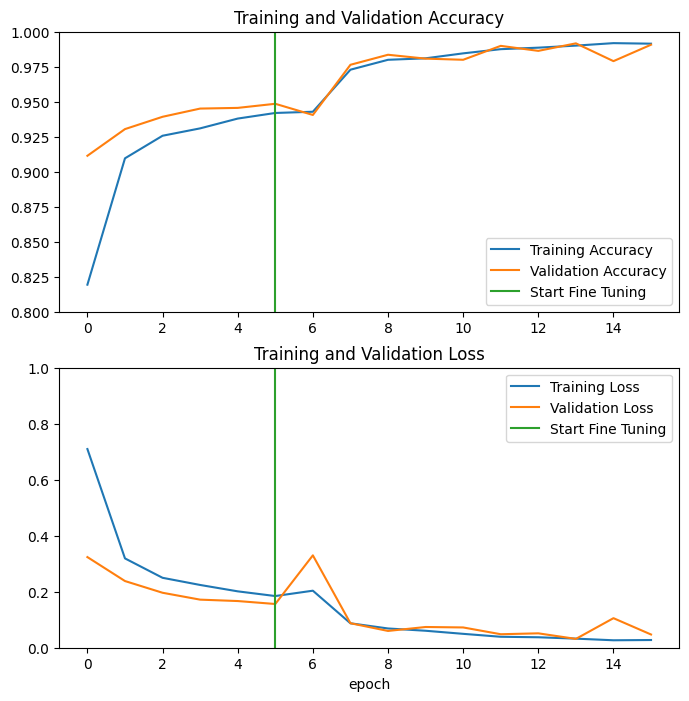

In [ ]:
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
loss, accuracy = model.evaluate(test_dataset)
print('Test accuracy :', accuracysi

193/193 ━━━━━━━━━━━━━━━━━━━━ 26s 134ms/step - accuracy: 0.9943 - loss: 0.0220
Test accuracy : 0.9920557737350464


Predictions:
 [38 17 30 16 26 11 13 35 25  5 25 20 17 26 16 26 24 13 17 30 25 36 29 27
  4 36 32 16  3  8 18 17]
Labels:
 [38 17 30 16 26 11 13 35 25  5 25 20 17 26 16 26 24 13 17 30 25 36 29 27
  4 36 32 16  3  8 18 17]


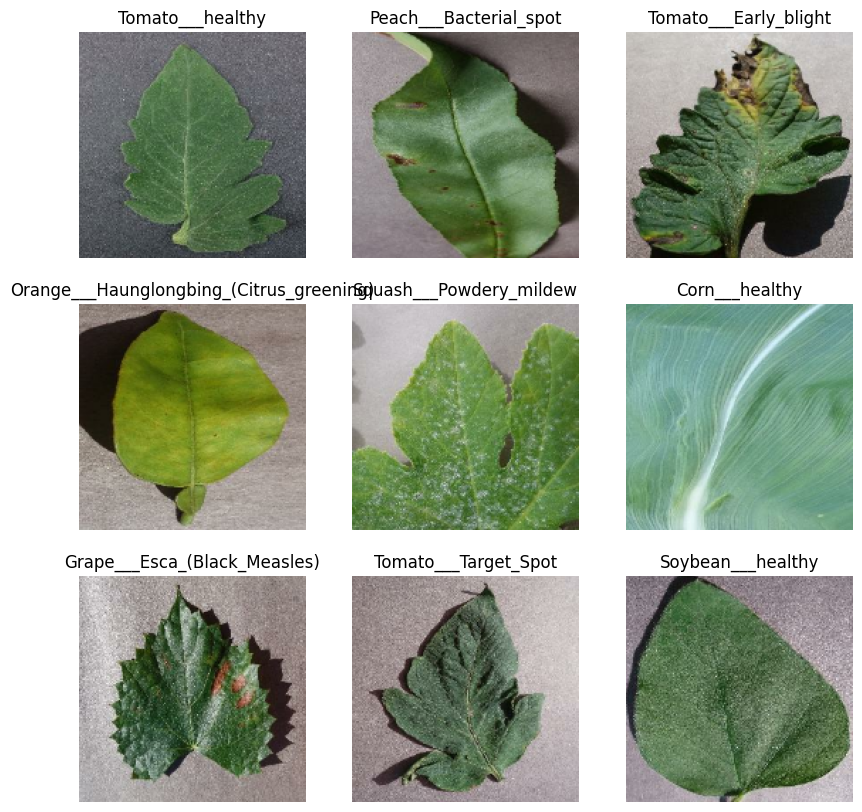

In [ ]:
# Retrieve a batch of images from the test set
image_batch, label_batch = test_dataset.as_numpy_iterator().next()
predictions = model.predict_on_batch(image_batch)
predictions = tf.argmax(predictions,axis=1)

print('Predictions:\n', predictions.numpy())
print('Labels:\n', label_batch)

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].astype("uint8"))
  plt.title(class_names[predictions[i]])
  plt.axis("off")

In [ ]:
import os
dataset_path = '/content/dataset'
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print('{}{}/'.format(indent, os.path.basename(root)))
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        print('{}{}'.format(subindent, f))

dataset/
    train/
        Tomato___healthy/
            image (1150).JPG
            image (184).JPG
            image (326).JPG
            image (618).JPG
            image (909).JPG
            image (572).JPG
            image (1111).JPG
            image (1424).JPG
            image (439).JPG
            image (1483).JPG
            image (554).JPG
            image (1485).JPG
            image (969).JPG
            image (190).JPG
            image (722).JPG
            image (85).JPG
            image (1052).JPG
            image (1164).JPG
            image (503).JPG
            image (771).JPG
            image (394).JPG
            image (61).JPG
            image (175).JPG
            image (1576).JPG
            image (1473).JPG
            image (929).JPG
            image (831).JPG
            image (665).JPG
            image (436).JPG
            image (765).JPG
            image (322).JPG
            image (293).JPG
            image (505).JPG
            image (649)

In [ ]:
print(f"Number of images in training dataset: {len(tf.io.gfile.glob('/content/dataset/train/*/*.JPG'))}")
print(f"Number of images in validation dataset: {len(tf.io.gfile.glob('/content/dataset/val/*/*.JPG'))}")
print(f"Number of images in test dataset: {len(tf.io.gfile.glob('/content/dataset/test/*/*.JPG'))}")

Number of images in training dataset: 47020
Number of images in validation dataset: 5868
Number of images in test dataset: 5887


In [ ]:
train_dir = "/content/dataset/train"
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    if os.path.isdir(class_path):
        num_images = len(os.listdir(class_path))
        print(f"{class_name}: {num_images}")

Tomato___healthy: 1272
Grape___Esca_(Black_Measles): 1106
Cherry___healthy: 800
Tomato___Leaf_Mold: 800
Grape___healthy: 800
Peach___healthy: 800
Apple___Cedar_apple_rust: 800
Cherry___Powdery_mildew: 841
Grape___Black_rot: 944
Tomato___Spider_mites Two-spotted_spider_mite: 1340
Tomato___Target_Spot: 1123
Tomato___Septoria_leaf_spot: 1416
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 4285
Pepper,_bell___Bacterial_spot: 800
Corn___Cercospora_leaf_spot Gray_leaf_spot: 800
Tomato___Early_blight: 800
Peach___Bacterial_spot: 1837
Background_without_leaves: 914
Potato___Late_blight: 800
Potato___healthy: 800
Corn___healthy: 929
Blueberry___healthy: 1201
Squash___Powdery_mildew: 1468
Apple___Apple_scab: 800
Corn___Northern_Leaf_Blight: 800
Orange___Haunglongbing_(Citrus_greening): 4405
Pepper,_bell___healthy: 1182
Tomato___Late_blight: 1527
Apple___healthy: 1316
Raspberry___healthy: 800
Apple___Black_rot: 800
Tomato___Tomato_mosaic_virus: 800
Strawberry___Leaf_scorch: 887
Grape___Leaf_blight_(Isari

193/193 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step


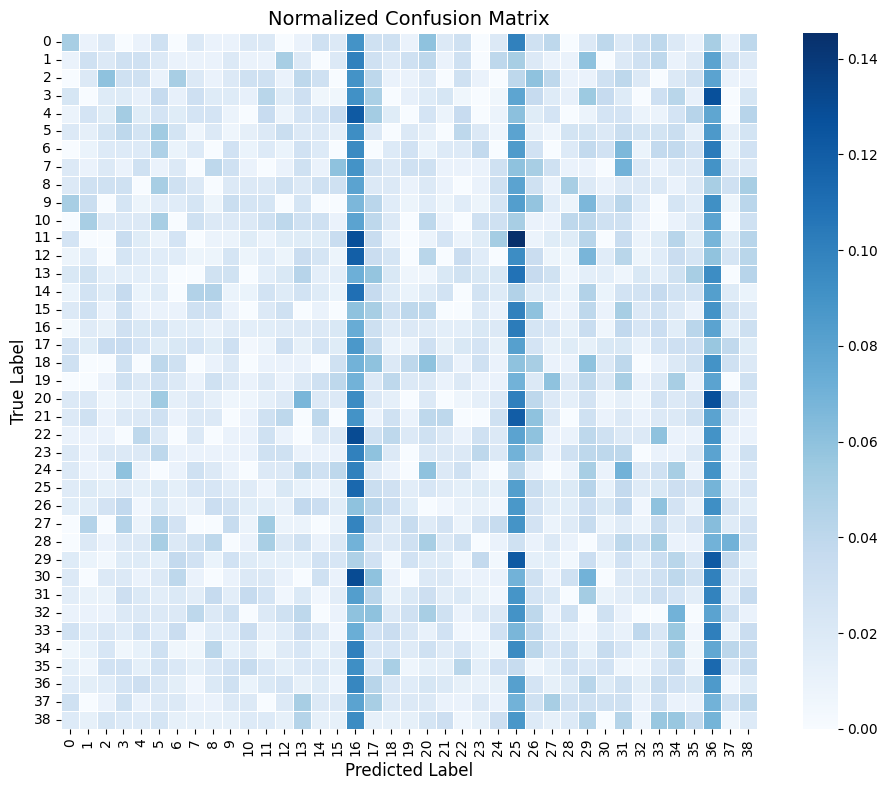

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_true = np.concatenate([y for x, y in test_dataset], axis=0)

y_prob = model.predict(test_dataset)
y_pred = np.argmax(y_prob, axis=1)
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype(np.float32) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized,
    cmap="Blues",
    square=True,
    cbar=True,
    xticklabels=np.arange(cm.shape[1]),
    yticklabels=np.arange(cm.shape[0]),
    linewidths=0.5
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Normalized Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()


=== TOP 5 BEST PERFORMING CLASSES (Highest AUC) ===
1. Apple___Apple_scab (Class 0) → AUC = 1.0000
2. Apple___Black_rot (Class 1) → AUC = 1.0000
3. Apple___Cedar_apple_rust (Class 2) → AUC = 1.0000
4. Background_without_leaves (Class 4) → AUC = 1.0000
5. Blueberry___healthy (Class 5) → AUC = 1.0000

=== BOTTOM 5 WORST PERFORMING CLASSES (Lowest AUC) ===
1. Tomato___Late_blight (Class 31) → AUC = 0.9999
2. Tomato___Early_blight (Class 30) → AUC = 0.9999
3. Pepper,_bell___Bacterial_spot (Class 19) → AUC = 0.9999
4. Corn___Cercospora_leaf_spot Gray_leaf_spot (Class 8) → AUC = 0.9998
5. Corn___Northern_Leaf_Blight (Class 10) → AUC = 0.9997


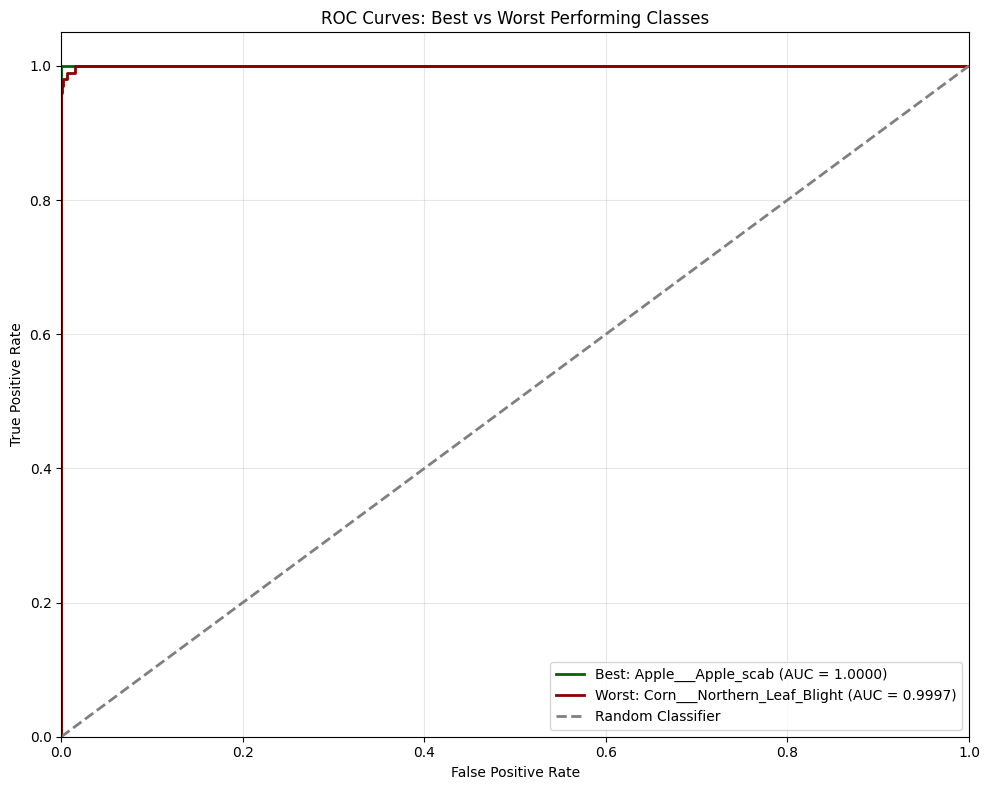

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import tensorflow as tf

y_true = []
y_prob = []

for batch_images, batch_labels in test_dataset:
    probs = model.predict(batch_images, verbose=0)
    y_prob.append(probs)
    y_true.append(batch_labels.numpy())

y_true = np.concatenate(y_true)
y_prob = np.concatenate(y_prob)
class_names = [
    'Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy',
    'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy',
    'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust',
    'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot',
    'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
    'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot',
    'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy',
    'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy',
    'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew',
    'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot',
    'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold',
    'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite',
    'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato___Tomato_mosaic_virus', 'Tomato___healthy'
]

n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

auc_list = [(i, class_names[i], roc_auc[i]) for i in range(n_classes)]

auc_list.sort(key=lambda x: x[2], reverse=True)
print("=== TOP 5 BEST PERFORMING CLASSES (Highest AUC) ===")
for rank, (idx, name, auc_val) in enumerate(auc_list[:5], 1):
    print(f"{rank}. {name} (Class {idx}) → AUC = {auc_val:.4f}")

print("\n=== BOTTOM 5 WORST PERFORMING CLASSES (Lowest AUC) ===")
for rank, (idx, name, auc_val) in enumerate(auc_list[-5:], 1):
    print(f"{rank}. {name} (Class {idx}) → AUC = {auc_val:.4f}")
plt.figure(figsize=(10, 8))
best_idx, best_name, best_auc = auc_list[0]
plt.plot(fpr[best_idx], tpr[best_idx], color='darkgreen', lw=2,
         label=f'Best: {best_name} (AUC = {best_auc:.4f})')
worst_idx, worst_name, worst_auc = auc_list[-1]
plt.plot(fpr[worst_idx], tpr[worst_idx], color='darkred', lw=2,
         label=f'Worst: {worst_name} (AUC = {worst_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Best vs Worst Performing Classes')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()